# Question 3: Demystifying Transformers – Building a Tiny Language Model

**Estimated Time:** 8 Hours  
**Total:** 70 Points  
**Objective:** Build a character-level autoregressive Transformer from scratch and understand attention, positional encoding, LayerNorm, and generation.

**Dataset:** Plain-text corpus (Bollywood plots / transliterated Hindi poetry / English text) with size $\ge 50$ KB and character-level tokenization ($V < 100$).

> Implement from scratch using only `torch.nn.Linear`, `torch.nn.LayerNorm`, `torch.nn.Embedding`, and basic tensor operations.  
> Do **not** use `torch.nn.TransformerDecoder` or HuggingFace.

## Part A: Theoretical Foundations [25 Points]

### 3A.1 Scaled Dot-Product Attention [5 pts]

$$
\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

**(a)** Explain why division by $\sqrt{d_k}$ is needed. If $q, k \sim \mathcal{N}(0,1)$ i.i.d., what is $\mathrm{Var}(q\cdot k)$, and how does that affect softmax?  
**(b)** What happens to softmax gradients if scaling is omitted and $d_k = 512$?

## Answers:

**(a)**
Without scaling i.e, division by $\sqrt{d_k}$, dot products grow large in magnitude as $d_k$ increases (since they sum $d_k$ terms), pushing the softmax into regions of near-zero gradient and making training slow. Dividing by $\sqrt{d_k}$ keeps the variance of the scores roughly constant at 1.

**(b)**
If scaling is omitted and $d_k = 512$, the variance of the dot product would be 512, leading to very large scores. The softmax would then produce near one-hot distributions, causing gradients to vanish and making it difficult for the model to learn effectively.

### 3A.2 Causal Masking [5 pts]

**(a)** Write the $4\times4$ causal mask (lower-triangular) for sequence length 4 using $0$ for allowed and $-\infty$ for blocked positions.  
**(b)** Explain why this mask is required for autoregressive language modeling but not used in BERT-style models.

In [146]:
## (a)
import torch
mask = torch.triu(torch.ones(4, 4), diagonal=1)
mask = mask.masked_fill(mask.bool(), -torch.inf)
print(mask)

tensor([[0., -inf, -inf, -inf],
        [0., 0., -inf, -inf],
        [0., 0., 0., -inf],
        [0., 0., 0., 0.]])


(b)
The causal mask is required in autoregressive language modeling to prevent the model from attending to future tokens during training, ensuring that predictions are based only on past and present context. This is becuase the fundamental task of autoregressive models is to predict the next token given previous tokens. Bert style models, on the other hand, are designed for masked language modeling where the model can attend to all tokens (including future ones) since the task is to predict randomly masked tokens rather than the next token in a sequence.

### 3A.3 Positional Encoding [5 pts]

**(a)** Write sinusoidal positional encoding formulas for $(pos, 2i)$ and $(pos, 2i+1)$.  
**(b)** Learned positional embeddings (GPT-2/LLaMA): give one advantage and one disadvantage compared to sinusoidal encodings.

**(a)**
$$PE(pos, 2i) = \sin\left(\frac{pos}{10000^{\frac{2i}{d_{model}}}}\right)$$
$$PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{\frac{2i+1}{d_{model}}}}\right)$$

**(b)**
Advantage: Learned positional embeddings can adapt to the specific dataset and task, potentially capturing more relevant positional information.  
Disadvantage: They may not generalize well to sequence lengths longer than those seen during training, whereas sinusoidal encodings can extrapolate to longer sequences.

### 3A.4 Why LayerNorm in Transformers? [6 pts]

**(a) Contrast with BatchNorm (3 pts).** For tensor shape $4\times10\times64$, explain why LayerNorm (feature-axis, per-token) is preferred over BatchNorm when sequences are padded to different lengths.  
**(b) Pre-Norm vs Post-Norm (3 pts).**

$$
\text{Post-Norm: } x \leftarrow \mathrm{LayerNorm}\big(x + \mathrm{Sublayer}(x)\big)
$$

$$
\text{Pre-Norm: } x \leftarrow x + \mathrm{Sublayer}\big(\mathrm{LayerNorm}(x)\big)
$$

Explain why Pre-Norm gives more stable gradients, especially in deeper models.

**(a)**
LayerNorm normalizes across the feature axis for each token independently, making it suitable for variable-length sequences with padding. BatchNorm normalizes across the batch dimension, which can be problematic when sequences have different lengths and padding tokens that should not contribute to the normalization. LayerNorm ensures that the normalization is consistent regardless of batch size or sequence length, while BatchNorm can produce unstable results due to varying batch statistics. 

**(b)**
Pre-Norm gives more stable gradients because it normalizes the input to the sublayer before applying the residual connection. This helps to prevent the explosion of gradients in deeper models, as the normalization step ensures that the input to the sublayer has a consistent scale. In contrast, Post-Norm applies the residual connection before normalization, which can lead to larger activations and unstable gradients as the depth increases.

### 3A.5 Multi-Head Attention [4 pts]

**(a)** If $d_{model}=64$ and $n_{heads}=4$, what are per-head dimensions of $Q, K, V$?  
**(b)** Why is multi-head attention more expressive than single-head attention with the same total parameter count? (2–3 sentences).

**(a)**
Per head dimensions of $Q, K, V$ are $d_k = d_v = \frac{d_{model}}{n_{heads}} = \frac{64}{4} = 16$.

**(b)**
Multi-head attention allows the model to attend to information from different representation subspaces at different positions. Each head can focus on different aspects of the input, capturing various relationships and patterns that a single head might miss. This parallel attention mechanism increases the model's capacity to learn complex dependencies without increasing the total parameter count significantly.  This can also be thought of how two 3x3 conv filter work same as one 5x5 conv filter, but with more non-linearity and less parameters. 

### Hint
For 3A.1(a), use:

$$
\mathrm{Var}(q\cdot k)=\sum_{j=1}^{d_k}\mathrm{Var}(q_jk_j)=d_k
$$

when entries are i.i.d. $\mathcal{N}(0,1)$.

## Part B: Practical Implementation [45 Points]

### 3B.1 Build the Transformer [15 pts]
Implement a decoder-only Transformer with:
- $d_{model}=64$, $n_{heads}=4$, $n_{layers}=3$
- Context window = 128 characters
- FFN hidden dimension = $4\times d_{model}=256$
- Dropout = 0.1

Must include learned token/position embeddings, masked multi-head self-attention, GELU FFN, residual connections, and **Pre-Norm** LayerNorm. Print total parameter count.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
## dataset shakespeare kaparthy 
data = open('input.txt', 'r').read()
data[:100]

'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou'

In [3]:
len(data)

1115394

In [4]:
ascii_list = []
for i in data:
    ascii_list.append(ord(i))

In [5]:
len(ascii_list), len(set(ascii_list))

(1115394, 65)

In [20]:
vocab = {i:ord(i) for i in set(data)}
print(vocab)

{'m': 109, 'u': 117, 'I': 73, 's': 115, 'i': 105, 'D': 68, '?': 63, ' ': 32, '-': 45, 't': 116, 'h': 104, 'M': 77, 'g': 103, 'o': 111, 'J': 74, 'a': 97, 'A': 65, 'q': 113, 'O': 79, 'r': 114, ':': 58, 'C': 67, 'w': 119, "'": 39, 'f': 102, 'v': 118, 'U': 85, 'Y': 89, 'P': 80, 'c': 99, 'Z': 90, ',': 44, 'e': 101, 'x': 120, '.': 46, 'V': 86, 'l': 108, 'E': 69, 'b': 98, 'k': 107, '&': 38, 'R': 82, 'Q': 81, '$': 36, '\n': 10, '3': 51, 'j': 106, '!': 33, 'B': 66, 'p': 112, ';': 59, 'L': 76, 'K': 75, 'N': 78, 'G': 71, 'X': 88, 'H': 72, 'F': 70, 'T': 84, 'd': 100, 'n': 110, 'z': 122, 'y': 121, 'W': 87, 'S': 83}


In [10]:
len(vocab)

65

In [74]:
class CharacterTokenizer:
    "a character tokenizer which has a vocabulary size V less than 100"
    def __init__(self, vocab):
        self.vocab_size = len(vocab)
        self.vocab = {char: idx for idx, char in enumerate(vocab)}
        self.inv_vocab = {v:k for k,v in self.vocab.items()}

    def encode(self, text):
        "encodes a string into a list of integers"
        try:
            return [self.vocab[i] for i in text]
        except KeyError as e:
            raise ValueError(f"Character {e} is not in vocabulary")

    def decode(self, tokens):
        "decodes a list of integers into a string"
        try:            
            return ''.join([self.inv_vocab[i] for i in tokens])
        except KeyError as e:
            raise ValueError(f"Token {e} is not in vocabulary")


In [75]:
tokenizer = CharacterTokenizer(vocab)

In [76]:
text = """buffalo buffalo,
           I'm a human"""
ids = tokenizer.encode(text)

In [77]:
print(ids)

[38, 1, 24, 24, 15, 36, 13, 7, 38, 1, 24, 24, 15, 36, 13, 31, 44, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 2, 23, 0, 7, 15, 7, 10, 1, 0, 15, 60]


In [78]:
print(tokenizer.decode(ids))

buffalo buffalo,
           I'm a human


In [79]:
from torch.utils.data import Dataset, DataLoader

class MyShakespeareDataset(Dataset):
    def __init__(self, data, tokenizer, stride=1, max_length=128):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(data)
        print(f"Total tokens: {len(token_ids)}")
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

        print(f"Created {len(self.input_ids)} input-target pairs.")
        
    def __len__(self):
        return len(self.input_ids)
        

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]



In [80]:
def create_dataloader(data, vocab, batch_size=4, max_length=128, 
                         stride=1, shuffle=False,
                        num_workers=0):

    # Initialize the tokenizer

    tokenizer = CharacterTokenizer(vocab)

    # Create dataset
    dataset = MyShakespeareDataset(data, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=num_workers,
    )

    return dataloader

In [90]:
loader = create_dataloader(data, vocab, max_length=128)

Total tokens: 1115394
Created 8715 input-target pairs.


In [82]:
data_iter = iter(loader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[57],
        [59],
        [63],
        [60]]), tensor([[ 4],
        [ 4],
        [32],
        [12]])]


In [83]:
data_iter = iter(loader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[57],
        [59],
        [63],
        [60]])

Targets:
 tensor([[ 4],
        [ 4],
        [32],
        [12]])


In [84]:
dataloader = create_dataloader(data, vocab, batch_size=8, max_length=128, stride=4, shuffle=False)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\n", targets)

Total tokens: 1115394
Created 8714 input-target pairs.
Inputs:
 tensor([[57,  4, 19,  3],
        [59,  4, 32,  7],
        [63, 32,  7, 39],
        [60, 12,  7, 13],
        [10, 32,  7, 49],
        [ 3, 13,  0, 32],
        [ 7,  0,  4,  3],
        [ 3, 31,  7, 32]])

Targets:
 tensor([[ 4, 19,  3,  9],
        [ 4, 32,  7,  9],
        [32,  7, 39, 60],
        [12,  7, 13, 60],
        [32,  7, 49, 15],
        [13,  0, 32, 31],
        [ 0,  4,  3, 32],
        [31,  7, 32, 19]])


In [85]:
vocab_size = 65
output_dim = 64

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [86]:
max_length = 128
dataloader = create_dataloader(
    data, vocab, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)

Total tokens: 1115394
Created 8714 input-target pairs.


In [87]:
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[57,  4, 19,  ...,  9, 13,  7],
        [59,  4, 32,  ..., 36, 20, 44],
        [63, 32,  7,  ..., 36, 39,  4],
        ...,
        [ 3, 13,  0,  ..., 13,  1, 19],
        [ 7,  0,  4,  ...,  4, 39, 32],
        [ 3, 31,  7,  ...,  7, 62, 13]])

Inputs shape:
 torch.Size([8, 128])


In [88]:
targets.shape

torch.Size([8, 128])

In [89]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)


torch.Size([8, 128, 64])


In [95]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x) # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim) 
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        attn_scores.masked_fill_(mask_bool, -torch.inf)
        
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ values).transpose(1, 2) 
        
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec) # optional projection

        return context_vec



In [ ]:
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], 
   [0.55, 0.87, 0.66], 
   [0.57, 0.85, 0.64], 
   [0.22, 0.58, 0.33], 
   [0.77, 0.25, 0.10], 
   [0.05, 0.80, 0.55]] 
)
batch = torch.stack((inputs, inputs), dim=0)

In [98]:
context_length = batch.shape[1] 
d_in, d_out = 3, 4
mha = MultiHeadAttention(
    d_in, d_out, context_length, 0.0, num_heads=2
)

context_vecs = mha(batch)

print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[-0.4534, -0.4184,  0.4423, -0.3203],
         [-0.3906, -0.2045,  0.4698, -0.3570],
         [-0.3695, -0.1345,  0.4780, -0.3691],
         [-0.3529, -0.1358,  0.4687, -0.3504],
         [-0.3545, -0.1583,  0.4504, -0.3250],
         [-0.3450, -0.1458,  0.4551, -0.3282]],

        [[-0.4534, -0.4184,  0.4423, -0.3203],
         [-0.3906, -0.2045,  0.4698, -0.3570],
         [-0.3695, -0.1345,  0.4780, -0.3691],
         [-0.3529, -0.1358,  0.4687, -0.3504],
         [-0.3545, -0.1583,  0.4504, -0.3250],
         [-0.3450, -0.1458,  0.4551, -0.3282]]], grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 6, 4])


In [99]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
        ))

In [101]:
class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(64, 4 * 64),
            GELU(),
            nn.Linear(4 * 64, 64),
        )

    def forward(self, x):
        return self.layers(x)

In [105]:
ffn = FeedForward()

# feed forward test
x = torch.rand(2, 3, 64) 
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 64])


In [138]:
class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=64,
            d_out=64,
            context_length=128,
            num_heads=4, 
            dropout=0.1,
            qkv_bias=False)
        self.ff = FeedForward()
        self.norm1 = nn.LayerNorm(64)
        self.norm2 = nn.LayerNorm(64)
        self.drop_shortcut = nn.Dropout(0.1)

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  

        return x
    
class TransformerBlockPostNorm(nn.Module):
    def __init__(self):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=64,
            d_out=64,
            context_length=128,
            num_heads=4, 
            dropout=0.1,
            qkv_bias=False)
        self.ff = FeedForward()
        self.norm1 = nn.LayerNorm(64)
        self.norm2 = nn.LayerNorm(64)
        self.drop_shortcut = nn.Dropout(0.1)

    def forward(self, x):
        shortcut = x
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  
        x = self.norm1(x)   

        shortcut = x
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  
        x = self.norm2(x)
        return x

In [127]:
class DecoderModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(65, 64)
        self.pos_emb = nn.Embedding(128, 64,)
        self.drop_emb = nn.Dropout(0.1)

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(3)])
        
        self.final_norm = nn.LayerNorm(64)
        self.out_head = nn.Linear(
            64, 65, bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [139]:
class DecoderModelPostNorm(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(65, 64)
        self.pos_emb = nn.Embedding(128, 64,)
        self.drop_emb = nn.Dropout(0.1)

        self.trf_blocks = nn.Sequential(
            *[TransformerBlockPostNorm() for _ in range(3)])
        
        self.final_norm = nn.LayerNorm(64)
        self.out_head = nn.Linear(
            64, 65, bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [128]:
model = DecoderModel()

In [129]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in the model: {total_params}")

Total parameters in the model: 166016


In [130]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([65, 64])
Output layer shape: torch.Size([65, 64])


In [131]:
total_size_bytes = total_params * 4
total_size_mb = total_size_bytes / (1024 * 1024)

print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 0.63 MB


In [133]:
model.train()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

for epoch in range(15):
    data_iter = iter(dataloader)
    total_loss = 0
    for batch_idx, (inputs, targets) in enumerate(data_iter):
        optimizer.zero_grad()
        logits = model(inputs)
        loss = loss_fn(logits.view(-1, logits.size(-1)), targets.view(-1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / (batch_idx + 1)
    print(f"Epoch {epoch+1}, Average Loss: {avg_loss:.4f}")

Epoch 1, Average Loss: 2.7263
Epoch 2, Average Loss: 2.4865
Epoch 3, Average Loss: 2.4213
Epoch 4, Average Loss: 2.3599
Epoch 5, Average Loss: 2.3076
Epoch 6, Average Loss: 2.2600
Epoch 7, Average Loss: 2.2152
Epoch 8, Average Loss: 2.1726
Epoch 9, Average Loss: 2.1330
Epoch 10, Average Loss: 2.0972
Epoch 11, Average Loss: 2.0618
Epoch 12, Average Loss: 2.0293
Epoch 13, Average Loss: 2.0000
Epoch 14, Average Loss: 1.9714
Epoch 15, Average Loss: 1.9462


### 3B.2 Pre-Norm vs Post-Norm Training Comparison [10 pts]
Train two variants for 3,000 iterations (or convergence) with Adam ($\eta=3\times10^{-4}$):
- Version A: Pre-LayerNorm
- Version B: Post-LayerNorm

Plot both training loss curves together and discuss:
- Which converges faster?
- Which reaches lower final loss?
- Any instability/spikes?

In [141]:
model_prenorm = DecoderModel()
model_postnorm = DecoderModelPostNorm()

In [143]:
model_postnorm.train()
model_prenorm.train()

loss_fn = nn.CrossEntropyLoss()
optimizer_prenorm = torch.optim.Adam(model_prenorm.parameters(), lr=3e-4)
optimizer_postnorm = torch.optim.Adam(model_postnorm.parameters(), lr=3e-4)

pre_norm_loss = []
post_norm_loss = []

for epoch in range(15):
    data_iter = iter(dataloader)
    total_loss_postnorm = 0
    total_loss_prenorm = 0
    for batch_idx, (inputs, targets) in enumerate(data_iter):
        optimizer_prenorm.zero_grad()
        logits = model_prenorm(inputs)
        loss_prenorm = loss_fn(logits.view(-1, logits.size(-1)), targets.view(-1))
        loss_prenorm.backward()
        optimizer_prenorm.step()
        total_loss_prenorm += loss_prenorm.item()
        pre_norm_loss.append(loss_prenorm.item())

        optimizer_postnorm.zero_grad()
        logits_postnorm = model_postnorm(inputs)
        loss_postnorm = loss_fn(logits_postnorm.view(-1, logits_postnorm.size(-1)), targets.view(-1))
        loss_postnorm.backward()
        optimizer_postnorm.step()
        total_loss_postnorm += loss_postnorm.item()
        post_norm_loss.append(loss_postnorm.item())


    avg_loss_postnorm = total_loss_postnorm / (batch_idx + 1)
    print(f"Epoch {epoch+1}, Average Loss Post-Norm: {avg_loss_postnorm:.4f}")
    avg_loss_prenorm = total_loss_prenorm / (batch_idx + 1)
    print(f"Epoch {epoch+1}, Average Loss Pre-Norm: {avg_loss_prenorm:.4f}")

Epoch 1, Average Loss Post-Norm: 2.7056
Epoch 1, Average Loss Pre-Norm: 2.7279
Epoch 2, Average Loss Post-Norm: 2.4764
Epoch 2, Average Loss Pre-Norm: 2.4889
Epoch 3, Average Loss Post-Norm: 2.4041
Epoch 3, Average Loss Pre-Norm: 2.4219
Epoch 4, Average Loss Post-Norm: 2.3386
Epoch 4, Average Loss Pre-Norm: 2.3581
Epoch 5, Average Loss Post-Norm: 2.2818
Epoch 5, Average Loss Pre-Norm: 2.3074
Epoch 6, Average Loss Post-Norm: 2.2273
Epoch 6, Average Loss Pre-Norm: 2.2594
Epoch 7, Average Loss Post-Norm: 2.1769
Epoch 7, Average Loss Pre-Norm: 2.2136
Epoch 8, Average Loss Post-Norm: 2.1329
Epoch 8, Average Loss Pre-Norm: 2.1707
Epoch 9, Average Loss Post-Norm: 2.0926
Epoch 9, Average Loss Pre-Norm: 2.1289
Epoch 10, Average Loss Post-Norm: 2.0555
Epoch 10, Average Loss Pre-Norm: 2.0893
Epoch 11, Average Loss Post-Norm: 2.0217
Epoch 11, Average Loss Pre-Norm: 2.0511
Epoch 12, Average Loss Post-Norm: 1.9910
Epoch 12, Average Loss Pre-Norm: 2.0169
Epoch 13, Average Loss Post-Norm: 1.9621
Epoch

In [149]:

for epoch in range(10):
    data_iter = iter(dataloader)
    total_loss_postnorm = 0
    total_loss_prenorm = 0
    for batch_idx, (inputs, targets) in enumerate(data_iter):
        optimizer_prenorm.zero_grad()
        logits = model_prenorm(inputs)
        loss_prenorm = loss_fn(logits.view(-1, logits.size(-1)), targets.view(-1))
        loss_prenorm.backward()
        optimizer_prenorm.step()
        total_loss_prenorm += loss_prenorm.item()
        pre_norm_loss.append(loss_prenorm.item())

        optimizer_postnorm.zero_grad()
        logits_postnorm = model_postnorm(inputs)
        loss_postnorm = loss_fn(logits_postnorm.view(-1, logits_postnorm.size(-1)), targets.view(-1))
        loss_postnorm.backward()
        optimizer_postnorm.step()
        total_loss_postnorm += loss_postnorm.item()
        post_norm_loss.append(loss_postnorm.item())


    avg_loss_postnorm = total_loss_postnorm / (batch_idx + 1)
    print(f"Epoch {15+epoch+1}, Average Loss Post-Norm: {avg_loss_postnorm:.4f}")
    avg_loss_prenorm = total_loss_prenorm / (batch_idx + 1)
    print(f"Epoch {15+epoch+1}, Average Loss Pre-Norm: {avg_loss_prenorm:.4f}")

Epoch 16, Average Loss Post-Norm: 1.8941
Epoch 16, Average Loss Pre-Norm: 1.9118
Epoch 17, Average Loss Post-Norm: 1.8759
Epoch 17, Average Loss Pre-Norm: 1.8916
Epoch 18, Average Loss Post-Norm: 1.8588
Epoch 18, Average Loss Pre-Norm: 1.8732
Epoch 19, Average Loss Post-Norm: 1.8434
Epoch 19, Average Loss Pre-Norm: 1.8563
Epoch 20, Average Loss Post-Norm: 1.8276
Epoch 20, Average Loss Pre-Norm: 1.8411
Epoch 21, Average Loss Post-Norm: 1.8134
Epoch 21, Average Loss Pre-Norm: 1.8275
Epoch 22, Average Loss Post-Norm: 1.8013
Epoch 22, Average Loss Pre-Norm: 1.8141
Epoch 23, Average Loss Post-Norm: 1.7890
Epoch 23, Average Loss Pre-Norm: 1.8027
Epoch 24, Average Loss Post-Norm: 1.7777
Epoch 24, Average Loss Pre-Norm: 1.7917
Epoch 25, Average Loss Post-Norm: 1.7674
Epoch 25, Average Loss Pre-Norm: 1.7830


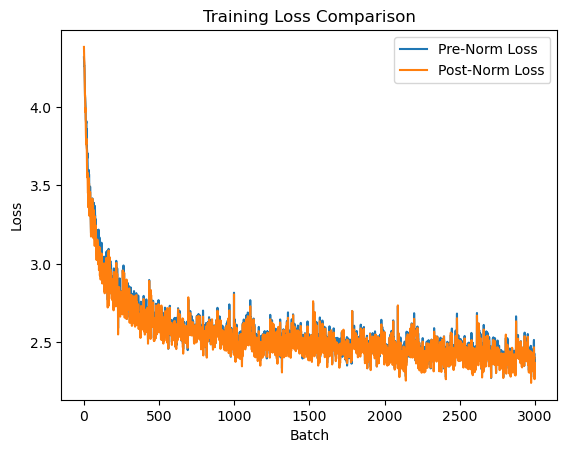

In [148]:
import matplotlib.pyplot as plt
plt.plot(pre_norm_loss[:3000], label='Pre-Norm Loss')
plt.plot(post_norm_loss[:3000], label='Post-Norm Loss')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.title('Training Loss Comparison')
plt.legend()
plt.show()

PreNorm and PostNorm losses are converging at the same rate and with same stability for this current model and dataset. It's almost that both of their curves are overlapping and identical. The PostNorm had a better start and so for first 15 epoches it continued to maintain and and final loss after 15 epoches is also slightly better than PreNorm. Even after continuing training for 10 more epoches, both of them are still maintaining the same pace and stability. 

### 3B.3 Text Generation [10 pts]
Implement:
```python
generate(model, prompt, max_len=200, temperature=1.0)
```

**(a)** Generate 200 characters from prompt `"The hero"` at $T=1.0$.  
**(b)** Generate at $T=0.2$ and $T=1.5$.  
**(c)** Explain in 3–4 sentences how temperature changes next-character distribution and output quality/diversity.

In [171]:
def generate(model, prompt, max_len = 200,temperature=1.0, context_size=128):
    idx = torch.Tensor(tokenizer.encode(prompt)).unsqueeze(0).int()
    for _ in range(max_len):
        
        idx_cond = idx[:, -context_size:]
        
        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)
        
        logits = logits[:, -1, :]  

        probas = torch.softmax(logits/temperature, dim=-1)  # (batch, vocab_size)

        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch, n_tokens+1)
    decoded_text = tokenizer.decode(idx.squeeze(0).tolist())
    return decoded_text


In [ ]:
model_postnorm.eval() # disable dropout

out = generate(
    model=model_postnorm,
    prompt="The Hero", 
    max_len=200, 
    temperature=1.0,
)
print("Output:", out)

Output: The Herow the shall be the so shall the shall the shall be the so so the some
The shall be the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the sha


In [176]:
model_postnorm.eval() 
out = generate(
    model=model_postnorm,
    prompt="The Hero", 
    max_len=200, 
    temperature=0.2,
)
print("Output:", out)

Output: The Herow the shall be the so shall the shall the shall be the so so the some
The shall be the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the sha


In [177]:
out = generate(
    model=model_postnorm,
    prompt="The Hero", 
    max_len=200, 
    temperature=1.5,
)
print("Output:", out)

Output: The Herow the shall be the so shall the shall the shall be the so so the some
The shall be the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the sha


There is no difference in the output quality and diversity of the generated text at different temperatures. The generated text is almost same at all three temperatures. This is probably because the model is not very good and is not able to learn a good distribution over the next character, so changing temperature does not have much effect on the output. Also the output is pretty much same tokens repeated again and again, so changing temperature does not have much effect on the output.

### 3B.4 Attention Visualization [10 pts]

**(a)** For a short input (e.g., `"the king"`), extract a $4\times4$ (or $8\times8$) attention matrix from one head in the first layer.  
**(b)** Plot heatmap (`matplotlib`) with keys on x-axis and queries on y-axis.  
**(c)** Repeat for one head in the last layer.  
**(d)** Compare first-layer vs last-layer attention in 2–3 sentences (local vs global patterns).

In [154]:
import math
def attention_from_block_input(att_module, x_in):
    B, T, _ = x_in.shape
    H = att_module.num_heads
    D = att_module.head_dim
    q = att_module.W_query(x_in).view(B, T, H, D).transpose(1, 2)  
    k = att_module.W_key(x_in).view(B, T, H, D).transpose(1, 2)    

    scores = (q @ k.transpose(2, 3)) / math.sqrt(D)                
    mask = att_module.mask[:T, :T].bool()
    scores = scores.masked_fill(mask, -torch.inf)
    attn = torch.softmax(scores, dim=-1)                           
    return attn

In [ ]:


model.eval()
text = "the king"
ids = torch.tensor(tokenizer.encode(text)).unsqueeze(0) 
T = ids.shape[1]

pos = torch.arange(T, device=ids.device)
x = model.tok_emb(ids) + model.pos_emb(pos)
x = model.drop_emb(x) 

x_first_in = model.trf_blocks[0].norm1(x)
A_first_all_heads = attention_from_block_input(model.trf_blocks[0].att, x_first_in)

x_mid = x
for blk in model.trf_blocks[:-1]:
    x_mid = blk(x_mid)

# last layer attention input
x_last_in = model.trf_blocks[-1].norm1(x_mid)
A_last_all_heads = attention_from_block_input(model.trf_blocks[-1].att, x_last_in)

head = 0
A_first = A_first_all_heads[0, head].detach().cpu().numpy()  
A_last = A_last_all_heads[0, head].detach().cpu().numpy()    
tokens = list(text)

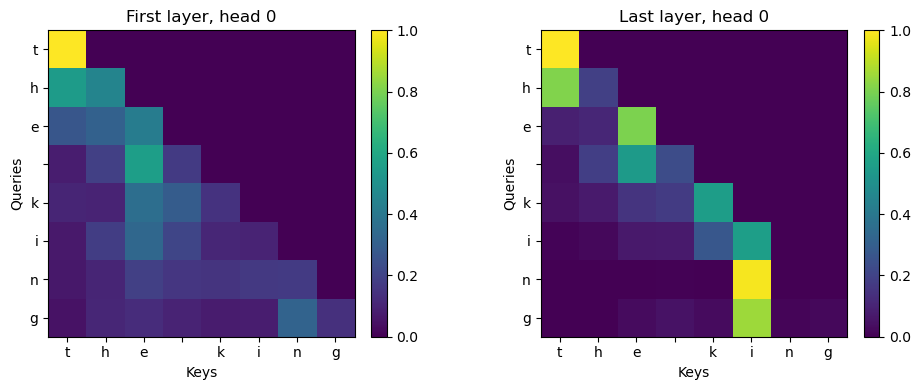

In [157]:
T = len(tokens)  # or T = A_first.shape[0]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

im0 = ax[0].imshow(A_first[:T, :T], cmap="viridis")
ax[0].set_xticks(range(T)); ax[0].set_yticks(range(T))
ax[0].set_xticklabels(tokens[:T]); ax[0].set_yticklabels(tokens[:T])
ax[0].set_xlabel("Keys"); ax[0].set_ylabel("Queries")
ax[0].set_title("First layer, head 0")
plt.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04)

im1 = ax[1].imshow(A_last[:T, :T], cmap="viridis")
ax[1].set_xticks(range(T)); ax[1].set_yticks(range(T))
ax[1].set_xticklabels(tokens[:T]); ax[1].set_yticklabels(tokens[:T])
ax[1].set_xlabel("Keys"); ax[1].set_ylabel("Queries")
ax[1].set_title("Last layer, head 0")
plt.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

It is clearly visible that the first layer attention is more local and focused on nearby characters, while the last layer attention is more global and attends to a wider range of characters in the input. How the n is attending to i it is almost near 0 where as in the last layer it is attending more to i than n. probably because in the first layer it is just trying to learn local patterns and in the last layer it is trying to learn more global patterns and relationships between characters.

## AI Attribution
- It helped me a lot in formatting this to a proper format espically the markdown cells latex part.
- I used it for learning how to extract attention weights and plot them using matplotlib. The code for extraction also was partly inspired from the code provided by AI. 

